# Chapter 11: Incident analysis agent

Companion notebook for [ch11/README.md](../README.md). Every number in the chapter comes from the saved outputs below or from `eval/results/`.

Prerequisites: `.env` configured, Docker with Compose v2, and (for the local model) Ollama with `gpt-oss:20b`. The notebook starts the stack itself, the same as:

```bash
cd ch11/01_main-chapter-code && docker compose up -d --build
```

In [1]:
import json
import subprocess
import sys
import time
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import pandas as pd
import tiktoken
from IPython.display import Image, Markdown, display

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import stack
from ch11_agent import tools
from ch11_agent.agent import run_agent
from ch11_agent.report import ranked, render_markdown
from ch11_agent.scoring import rank_of_root_cause
from llmprod import get_settings

IMAGES = HERE.parent / "images"
settings = get_settings()
HOSTED, LOCAL = settings.llm_model, "gpt-oss:20b"


def openrouter_usage() -> float:
    r = httpx.get("https://openrouter.ai/api/v1/key", timeout=10,
                  headers={"Authorization": f"Bearer {settings.llm_api_key}"})
    return r.json()["data"]["usage"]


spend_before = openrouter_usage()
stack.compose("up", "-d", "--build")
stack.wait_ready()
ps = subprocess.run(["docker", "compose", "ps", "--format", "{{.Service}}\t{{.Image}}\t{{.Ports}}"],
                    cwd=HERE, capture_output=True, text=True).stdout
print(ps)
print("hosted model:", HOSTED, "| local model:", LOCAL)

checkout	ch11-checkout	0.0.0.0:8011->8011/tcp, [::]:8011->8011/tcp
grafana	grafana/grafana:13.2.5	0.0.0.0:3011->3000/tcp, [::]:3011->3000/tcp
loki	grafana/loki:3.7.9	0.0.0.0:3101->3100/tcp, [::]:3101->3100/tcp
prometheus	prom/prometheus:v3.16.0	0.0.0.0:9091->9090/tcp, [::]:9091->9090/tcp

hosted model: openai/gpt-6-luna | local model: gpt-oss:20b


## A healthy baseline

`loadgen.py` sends about 6 requests per second (Poisson arrivals) to three routes. We reset the fault, recreate Prometheus and Loki so no older incident leaks into this one, and let healthy traffic run for a minute. Then we call each of the agent's tools by hand, exactly as the model will.

In [2]:
ALERT = ("Checkout Overview alert: elevated errors and/or latency on service `checkout` "
         "(thresholds: 5xx ratio > 5% or p95 latency > 2s for 5 minutes). Find out why.")


def inject(scenario: str) -> dict:
    out = subprocess.run([sys.executable, "inject_fault.py", "--scenario", scenario],
                         cwd=HERE, check=True, capture_output=True, text=True).stdout
    return json.loads(out)


load = subprocess.Popen([sys.executable, "loadgen.py", "--rps", "6"], cwd=HERE,
                        stdout=subprocess.DEVNULL)
inject("none")
stack.fresh_telemetry()
time.sleep(60)
print(tools.query_prometheus('sum by (route, status) (rate(http_requests_total{job="checkout"}[1m]))', "2m"))
print()
print(tools.get_deploys("24h"))
print()
print(tools.search_runbooks("db pool exhausted connection")[:700], "...")

{route=/checkout,status=200}: first=0.2327 min=0.2327 max=2.618 last=2.618 | samples over window: 0.2327 0.7211 1.384 1.826 2.345 2.618
{route=/checkout,status=402}: first=0 min=0 max=0.09091 last=0.09091 | samples over window: 0 0 0.02035 0.05829 0.07273 0.09091
{route=/checkout,status=500}: first=0 min=0 max=0 last=0 | samples over window: 0 0 0 0 0 0
{route=/checkout,status=503}: first=0 min=0 max=0 last=0 | samples over window: 0 0 0 0 0 0
{route=/checkout,status=504}: first=0 min=0 max=0 last=0 | samples over window: 0 0 0 0 0 0
{route=/orders/{order_id},status=200}: first=0.1551 min=0.1551 max=1.382 last=1.382 | samples over window: 0.1551 0.3125 0.5291 0.8161 1.291 1.382
{route=/orders/{order_id},status=503}: first=0 min=0 max=0 last=0 | samples over window: 0 0 0 0 0 0
{route=/products,status=200}: first=0.4265 min=0.4265 max=2.073 last=2.018 | samples over window: 0.4265 0.7692 1.404 1.69 2.018 2.018
... 1 more series omitted; add a sum by (...)

- v2026.11.09-1 sha=6eba58a de

## Inject an incident: DB pool exhaustion

`inject_fault.py` flips the simulated service into a fault through `/admin/state`. In `db-pool-exhaustion`, a slow inventory-lock query on `/checkout` holds each pooled connection for 3 to 4.5 seconds. At ~2.4 checkouts per second that needs about 9 of the 10 connections on average, so the pool sits at its limit, requests on *every* route queue for a connection, and the ones that wait longer than 2 seconds fail with a 503. We let it build for two minutes, then take a screenshot of the Grafana dashboard an on-call engineer would open.

{'injected_at': '2026-11-09T13:29:02Z', 'scenario': 'db-pool-exhaustion', 'deploy_version': 'v2026.11.09-1', 'provider': 'paypal', 'pool_size': 10, 'pool_in_use': 0}


(node:3011414) Warning: The 'NO_COLOR' env is ignored due to the 'FORCE_COLOR' env being set.
(Use `node --trace-warnings ...` to show where the warning was created)


saved /home/a.saugi/llm-in-production/ch11/images/11-grafana-db-pool-incident.png


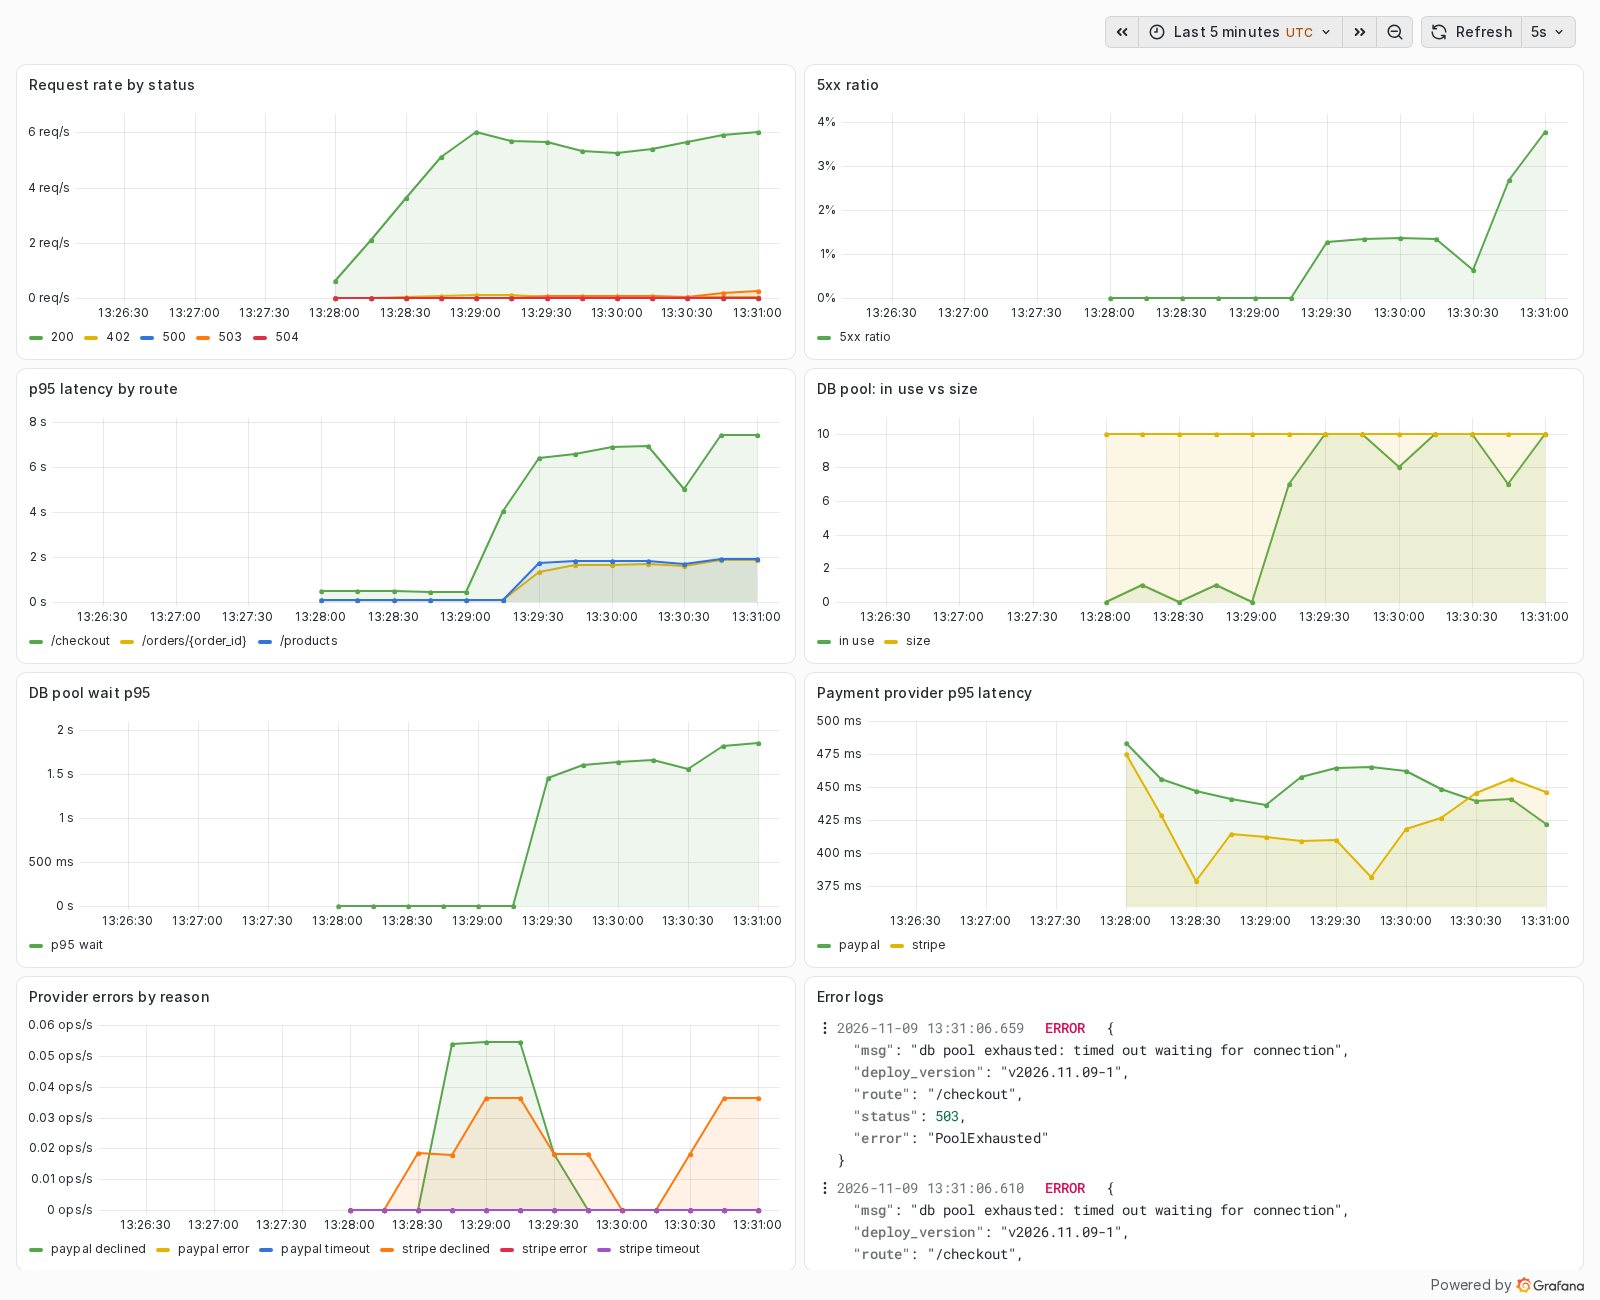

In [3]:
print(inject("db-pool-exhaustion"))
time.sleep(120)
shot = IMAGES / "11-grafana-db-pool-incident.png"
subprocess.run([sys.executable, str(HERE.parents[1] / "tools" / "screenshot.py"),
                "http://localhost:3011/d/checkout-overview/checkout-overview?orgId=1&kiosk&from=now-5m&to=now",
                str(shot), "--width", "1600", "--height", "1300", "--delay-ms", "6000"], check=True)
display(Image(filename=shot, width=900))

## v0: hand the model the raw API responses

The obvious tool implementation returns what Prometheus and Loki return: the full JSON matrix with every sample, and raw log lines. We call the same queries both ways and count tokens with `o200k_base` (an OpenAI tokenizer, used here as an approximation for every model).

In [4]:
enc = tiktoken.get_encoding("o200k_base")
QUERIES = [
    ("prom", 'sum by (route, status) (rate(http_requests_total{job="checkout"}[1m]))'),
    ("prom", 'histogram_quantile(0.95, sum by (le, route) (rate(http_request_duration_seconds_bucket{job="checkout"}[1m])))'),
    ("prom", 'db_pool_connections_in_use{job="checkout"}'),
    ("prom", 'http_request_duration_seconds_bucket{job="checkout"}'),
    ("loki", '{service="checkout", level="error"}'),
    ("loki", '{service="checkout"}'),
]
rows = []
for kind, q in QUERIES:
    fn = tools.query_prometheus if kind == "prom" else tools.query_loki
    raw, summ = fn(q, "15m", summarize=False), fn(q, "15m")
    rows.append({"tool": kind, "query": q[:60], "raw_tokens": len(enc.encode(raw)),
                 "summary_tokens": len(enc.encode(summ))})
sizes = pd.DataFrame(rows)
sizes["ratio"] = (sizes.raw_tokens / sizes.summary_tokens).round(1)
print(sizes.to_string(index=False))
print("\ntotal raw tokens:", sizes.raw_tokens.sum(), "| total summarized:", sizes.summary_tokens.sum())

tool                                                        query  raw_tokens  summary_tokens  ratio
prom sum by (route, status) (rate(http_requests_total{job="checko        1909             437    4.4
prom histogram_quantile(0.95, sum by (le, route) (rate(http_reque         728             178    4.1
prom                   db_pool_connections_in_use{job="checkout"}         190              31    6.1
prom         http_request_duration_seconds_bucket{job="checkout"}        8307             379   21.9
loki                          {service="checkout", level="error"}        1201             232    5.2
loki                                         {service="checkout"}        9939             197   50.5

total raw tokens: 22274 | total summarized: 1454


In [5]:
print("--- raw (first 600 chars) ---")
print(tools.query_loki('{service="checkout", level="error"}', "15m", summarize=False)[:600])
print("\n--- summarized ---")
print(tools.query_loki('{service="checkout", level="error"}', "15m"))

--- raw (first 600 chars) ---
1794231066659838464 {"msg": "db pool exhausted: timed out waiting for connection", "deploy_version": "v2026.11.09-1", "route": "/checkout", "status": 503, "error": "PoolExhausted"}
1794231066610178048 {"msg": "db pool exhausted: timed out waiting for connection", "deploy_version": "v2026.11.09-1", "route": "/checkout", "status": 503, "error": "PoolExhausted"}
1794231066581621760 {"msg": "db pool exhausted: timed out waiting for connection", "deploy_version": "v2026.11.09-1", "route": "/checkout", "status": 503, "error": "PoolExhausted"}
1794231058235119872 {"msg": "db pool exhausted: timed out

--- summarized ---
21 log lines in 4 distinct patterns (most frequent first):
- x13 [13:29:24Z..13:31:06Z] level=error msg=db pool exhausted: timed out waiting for connection route=/checkout status=503 deploy_version=v2026.11.09-1 error=PoolExhausted
- x5 [13:29:23Z..13:30:32Z] level=error msg=db pool exhausted: timed out waiting for connection route=/products statu

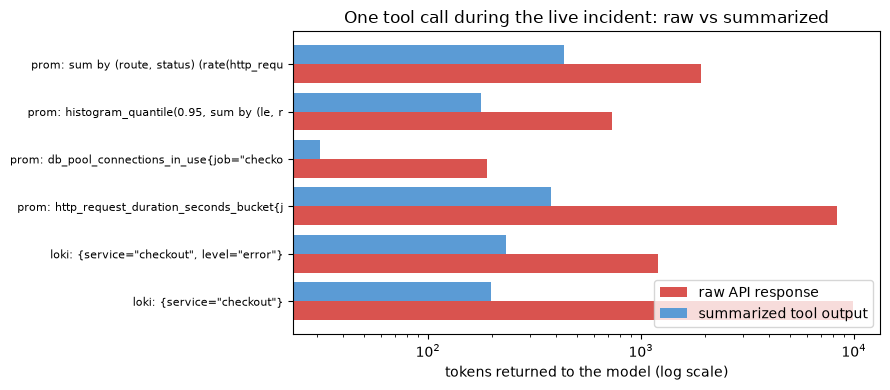

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
labels = [f"{r.tool}: {r.query[:38]}" for r in sizes.itertuples()]
y = range(len(sizes))
ax.barh([i + 0.2 for i in y], sizes.raw_tokens, height=0.4, label="raw API response", color="#d9534f")
ax.barh([i - 0.2 for i in y], sizes.summary_tokens, height=0.4, label="summarized tool output", color="#5b9bd5")
ax.set_yticks(list(y), labels, fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("tokens returned to the model (log scale)")
ax.set_title("One tool call during the live incident: raw vs summarized")
ax.legend(loc="lower right")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(IMAGES / "11-tool-output-size.png", dpi=150)
plt.show()

## Run the agent on the live incident

The agent gets only the alert text. It decides which tools to call, then writes an `IncidentReport` under a strict JSON schema, which we render as a Markdown postmortem draft.

In [7]:
def show_trace(res) -> None:
    for t in res.trace:
        print(f"step {t['step']} {t['tool']:16s} {t['chars']:5d} chars  {json.dumps(t['args'])[:110]}")
    print(f"\nmodel={res.model} steps={res.steps} prompt_tokens={res.prompt_tokens} "
          f"max_prompt={res.max_prompt_tokens} completion_tokens={res.completion_tokens} "
          f"latency={res.latency_s:.1f}s cost=${res.cost_usd:.4f} error={res.error}")


hosted = run_agent(ALERT, HOSTED)
show_trace(hosted)
print("root cause rank:", rank_of_root_cause(hosted.report, "db-pool-exhaustion"))

step 1 query_prometheus  1007 chars  {"promql": "sum by (route, status) (rate(http_requests_total{job=\"checkout\"}[1m]))", "range": "15m"}
step 1 query_prometheus   387 chars  {"promql": "histogram_quantile(0.95, sum by (route, le) (rate(http_request_duration_seconds_bucket{job=\"check
step 1 get_deploys        120 chars  {"since": "24h"}
step 1 query_loki         747 chars  {"logql": "{service=\"checkout\", level=\"error\"} | json", "range": "15m"}
step 2 query_prometheus   962 chars  {"promql": "sum by (le) (rate(db_pool_wait_seconds_bucket{job=\"checkout\"}[1m]))", "range": "15m"}
step 2 query_prometheus    71 chars  {"promql": "sum by (job) (db_pool_connections_in_use{job=\"checkout\"}) / sum by (job) (db_pool_size{job=\"che
step 2 query_prometheus   627 chars  {"promql": "sum by (provider, reason) (rate(payment_provider_errors_total{job=\"checkout\"}[1m]))", "range": "
step 2 search_runbooks   1209 chars  {"query": "checkout db pool exhausted PoolExhausted connection pool severit

In [8]:
postmortem = render_markdown(hosted.report, alert=ALERT, model=hosted.model, steps=hosted.steps,
                             cost_usd=hosted.cost_usd)
(HERE / "reports").mkdir(exist_ok=True)
(HERE / "reports" / "live-db-pool-exhaustion-hosted.md").write_text(postmortem)
display(Markdown(postmortem))

# Incident report (draft, generated by an AI agent)

*Generated 2026-11-09 13:31 UTC by `openai/gpt-6-luna` in 8 tool steps, cost $0.0032. A human must review it before it is shared.*

**Alert:** Checkout Overview alert: elevated errors and/or latency on service `checkout` (thresholds: 5xx ratio > 5% or p95 latency > 2s for 5 minutes). Find out why.

## Summary

Checkout is experiencing elevated latency and 503 errors due to DB connection pool exhaustion. The evidence supports this as the primary cause; the available data does not establish whether it is driven by a traffic spike, slow queries, or an application regression. The alert is consistent with a SEV2 incident under the runbook; escalate if checkout is effectively down.

## Impact

The /checkout route has rising 503s, with related 503 errors on /products and /orders/{order_id}. Its reported p95 reached 7.624 seconds in the 15-minute view, exceeding the 2-second threshold. Logs show PoolExhausted errors. A request-rate-derived 5xx ratio is not reliably calculable from the returned summaries, so the magnitude of the error-ratio breach is unconfirmed.

## Timeline (UTC)

- 2026-11-09 08:27:44 UTC — v2026.11.09-1 deployed (sha=6eba58a), adding a gift-message field to checkout.
- 2026-11-09 13:27:45 UTC — one logged PayPal provider timeout on /checkout (status=504).
- 2026-11-09 13:29:23 UTC — first observed DB pool exhaustion errors on /products and /orders/{order_id}.
- 2026-11-09 13:29:24 UTC — first observed DB pool exhaustion error on /checkout.
- 2026-11-09 13:31:06 UTC — latest observed DB pool exhaustion error on /checkout in the queried log window.
- By 2026-11-09 13:31:11 UTC — 15-minute view reports /checkout p95 at 7.624 seconds and DB pool utilization at 1.0 (connections in use equal pool size); DB pool wait histogram rate is elevated.

## Hypotheses, most likely first

### 1. DB connection pool exhaustion is the primary cause of the current checkout latency and 503 errors. (confidence 98%)

- Loki showed 13 /checkout errors from 13:29:24Z to 13:31:06Z with msg="db pool exhausted: timed out waiting for connection", status=503, error=PoolExhausted.
- The same PoolExhausted pattern appeared on /products (5 logs) and /orders/{order_id} (2 logs), indicating impact across routes.
- DB pool utilization reached 1.0 in the 15-minute query.
- The DB pool wait histogram's +Inf rate rose to 6.527 in the 15-minute view.

### 2. A traffic increase is exhausting the DB pool. (confidence 42%)

- The /checkout request rate in the 15-minute view rose from 0.1613 to 2.436 requests per second.
- The /products request rate rose from 0.2957 to 2.073 requests per second.
- The reported pool utilization reached 1.0.

### 3. Slow queries or long-held DB connections are exhausting the pool. (confidence 32%)

- Pool utilization reached 1.0 while the DB pool wait histogram's +Inf rate rose to 6.527.
- PoolExhausted timeout logs appeared across /checkout, /products, and /orders/{order_id}.

### 4. A recent deploy introduced a regression that is contributing to the pool exhaustion. (confidence 25%)

- The only deploy returned in the past 24 hours was v2026.11.09-1 at 2026-11-09T08:27:44Z, described as adding a gift-message field to checkout.
- All 21 queried error logs were tagged deploy_version=v2026.11.09-1.
- The deploy preceded the first observed PoolExhausted log at 13:29:23Z by about five hours.

### 5. Payment-provider failures are the primary cause of the current alert. (confidence 2%)

- There was one logged PayPal timeout at 13:27:45Z, with status=504.
- In the 15-minute provider error query, timeout rates for both paypal and stripe ended at 0.

## Proposed next actions (a human decides and executes these)

1. Have the incident commander classify this as SEV2 per the DB pool exhaustion guidance, and escalate to SEV1 if checkout is effectively down.
2. Have the checkout and database on-call verify pool utilization, Postgres connection headroom, and active checkout query durations to distinguish a traffic spike from slow queries or connection retention.
3. If slow queries are confirmed, have a DBA capture query text and follow the runbook before considering termination of specifically identified checkout sessions; do not target replication or migration sessions.
4. If a traffic spike is confirmed and Postgres has sufficient max_connections headroom across replicas, have the service owner consider raising db_pool_size in small steps, such as from 10 to 20, and plan to revert after the incident.
5. Have the release owner assess whether v2026.11.09-1 could be related; consider rollback to a known-good version only if the investigation supports a deploy regression.
6. Continue monitoring per-route 5xx ratios, p95 latency, pool utilization, and pool wait, and verify recovery after any human-approved mitigation.


The same incident, investigated by `gpt-oss:20b` running locally through Ollama. This cell only runs when `CH11_LOCAL=1` is set: a 20B model needs the GPU, and on the day this notebook was executed the RTX 3090 was fully occupied by another workload (Ollama fell back to CPU at a few tokens per second), so the local run was skipped. Set the variable and re-execute to fill it in.

In [9]:
import os

if os.getenv("CH11_LOCAL") == "1":
    local = run_agent(ALERT, LOCAL)
    show_trace(local)
    if local.report:
        print("root cause rank:", rank_of_root_cause(local.report, "db-pool-exhaustion"))
        for h in ranked(local.report):
            print(f"  {h.confidence:.2f}  {h.hypothesis}")
        (HERE / "reports" / "live-db-pool-exhaustion-local.md").write_text(render_markdown(
            local.report, alert=ALERT, model=local.model, steps=local.steps, cost_usd=0.0))
else:
    print("local run skipped (set CH11_LOCAL=1 to run gpt-oss:20b through Ollama)")

step 1 query_prometheus   114 chars  {"promql": "sum(rate(http_requests_total{service=\"checkout\",status=~\"5..\"}[1m])) / sum(rate(http_requests_
step 2 query_prometheus    92 chars  {"promql": "sum(rate(http_requests_total{status=~\"5..\"}[1m])) / sum(rate(http_requests_total[1m]))", "range"
step 3 query_prometheus   108 chars  {"promql": "histogram_quantile(0.95, sum(rate(http_request_duration_seconds_bucket[1m])) by (le))", "range": "
step 4 query_loki          92 chars  {"logql": "{service=\"checkout\",level=\"error\"} | json | msg=~\".*\" | pattern=msg", "range": "10m"}
step 5 query_loki         747 chars  {"logql": "{service=\"checkout\",level=\"error\"} | json | msg=~\".*\"", "range": "10m"}
step 6 query_prometheus   114 chars  {"promql": "db_pool_connections_in_use{service=\"checkout\"}", "range": "5m"}
step 7 query_prometheus    71 chars  {"promql": "db_pool_connections_in_use", "range": "5m"}
step 8 query_prometheus    75 chars  {"promql": "db_pool_size", "range": "5m"}

mo

In [10]:
print(inject("none"))
load.terminate()
_ = load.wait()

{'injected_at': '2026-11-09T13:31:44Z', 'scenario': 'none', 'deploy_version': 'v2026.11.09-1', 'provider': 'paypal', 'pool_size': 10, 'pool_in_use': 10}


## Results: 3 scenarios × 2 models

`eval/run_eval.py` repeats this for every scenario: fresh telemetry, 75 s of healthy traffic, inject, 100 s of fault, then run the agent and score whether the injected root cause is the top-ranked hypothesis. The runs were produced on the command line (about 11 minutes per model and variant) and saved to `eval/results/`; this cell only reads them:

```bash
cd ch11/01_main-chapter-code
uv run python eval/run_eval.py --models openai/gpt-6-luna --repeats 3 --out eval/results/agent-eval-gpt-6-luna.json
uv run python eval/run_eval.py --models anthropic/claude-haiku-5.5 --repeats 3 --out eval/results/agent-eval-claude-haiku-5.5.json
uv run python eval/run_eval.py --models openai/gpt-6-luna --repeats 3 --raw-tools --out eval/results/agent-eval-raw-gpt-6-luna.json
# local model (needs a free GPU): --models gpt-oss:20b --workers 1 --out eval/results/agent-eval-gpt-oss-20b.json
```

In [11]:
runs = pd.DataFrame([r for p in sorted((HERE / "eval" / "results").glob("agent-eval-*.json"))
                     for r in json.loads(p.read_text())])
runs["variant"] = runs.summarize.map({True: "summarized", False: "raw (v0)"})
runs["top1"] = runs["rank"] == 1
summary = runs.groupby(["variant", "model", "scenario"]).agg(
    runs=("top1", "size"), top1=("top1", "sum"), errors=("error", lambda s: s.notna().sum()),
    steps=("steps", "mean"), prompt_tokens=("prompt_tokens", "mean"),
    max_prompt=("max_prompt_tokens", "max"), latency_s=("latency_s", "median"),
    cost_usd=("cost_usd", "mean")).round(4)
print(summary.to_string())

                                                                runs  top1  errors   steps  prompt_tokens  max_prompt  latency_s  cost_usd
variant    model                      scenario                                                                                            
raw (v0)   openai/gpt-6-luna          bad-deploy                   3     3       0  3.0000     69079.0000       23782       19.3    0.0062
                                      db-pool-exhaustion           3     3       0  4.3333     48793.6667       13780       19.3    0.0039
                                      payment-provider-timeout     3     3       0  5.6667     88408.0000       19388       21.9    0.0052
summarized anthropic/claude-haiku-5.5 bad-deploy                   3     3       0  2.3333     13119.6667        4906       15.8    0.0030
                                      db-pool-exhaustion           3     1       0  3.3333     20838.6667        6344       22.0    0.0041
                           

In [12]:
overall = runs.groupby(["variant", "model"]).agg(
    runs=("top1", "size"), top1_rate=("top1", "mean"), prompt_tokens=("prompt_tokens", "mean"),
    p50_latency_s=("latency_s", "median"), p95_latency_s=("latency_s", lambda s: s.quantile(0.95)),
    cost_per_run=("cost_usd", "mean"), cost_total=("cost_usd", "sum"))
overall["top1_rate"] = (overall.top1_rate * 100).round(1)
print(overall.round(4).to_string())

                                       runs  top1_rate  prompt_tokens  p50_latency_s  p95_latency_s  cost_per_run  cost_total
variant    model                                                                                                             
raw (v0)   openai/gpt-6-luna              9      100.0     68760.2222           19.3          25.56        0.0051      0.0457
summarized anthropic/claude-haiku-5.5     9       77.8     16617.8889           18.7          22.78        0.0035      0.0312
           gpt-oss:20b                    9       22.2     11121.5556            9.6          12.10        0.0000      0.0000
           openai/gpt-6-luna              9      100.0     18081.4444           19.6          24.24        0.0021      0.0187


In [13]:
for r in runs[~runs.top1].itertuples():
    print(f"{r.variant:11s} {r.model:18s} {r.scenario:25s} r{r.repeat} rank={r.rank} "
          f"err={r.error}\n    top: {r.top_hypothesis}")

summarized  anthropic/claude-haiku-5.5 db-pool-exhaustion        r1 rank=2.0 err=nan
    top: Deploy v2026.11.07-1 (gift-message change) causes DB connection pool exhaustion, either via added queries or connections held longer, or because pool size is insufficient for the new load.
summarized  anthropic/claude-haiku-5.5 db-pool-exhaustion        r2 rank=nan err=nan
    top: Database connection pool exhaustion caused by deploy v2026.11.07-1 (gift-message change holding connections longer or adding load), producing 503 PoolExhausted across checkout routes
summarized  gpt-oss:20b        db-pool-exhaustion        r1 rank=nan err=nan
    top: Database connection pool exhaustion due to increased load after deployment.
summarized  gpt-oss:20b        db-pool-exhaustion        r2 rank=nan err=ValidationError: 5 validation errors for IncidentReport
impact
  Field required [type=missing, input_value={'incident_id': 'checkout... transient DB errors.']}, input_type=dict]
    For further information

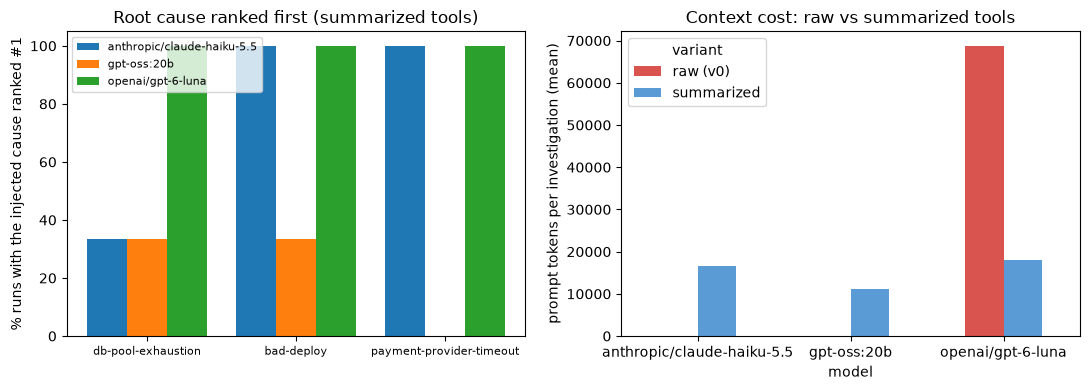

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
hits = summary.reset_index()
hits = hits[hits.variant == "summarized"]
scen = ["db-pool-exhaustion", "bad-deploy", "payment-provider-timeout"]
models = sorted(hits.model.unique())
w = 0.8 / len(models)
for i, m in enumerate(models):
    sub = hits[hits.model == m].set_index("scenario").reindex(scen)
    axes[0].bar([x + i * w for x in range(len(scen))], sub.top1 / sub.runs * 100, width=w, label=m)
axes[0].set_xticks([x + w * (len(models) - 1) / 2 for x in range(len(scen))], scen, fontsize=8)
axes[0].set_ylabel("% runs with the injected cause ranked #1")
axes[0].set_ylim(0, 105)
axes[0].set_title("Root cause ranked first (summarized tools)")
axes[0].legend(fontsize=8)
tok = runs.groupby(["model", "variant"]).prompt_tokens.mean().unstack()
tok.plot.bar(ax=axes[1], color={"raw (v0)": "#d9534f", "summarized": "#5b9bd5"}, rot=0)
axes[1].set_ylabel("prompt tokens per investigation (mean)")
axes[1].set_title("Context cost: raw vs summarized tools")
fig.tight_layout()
fig.savefig(IMAGES / "11-eval.png", dpi=150)
plt.show()

In [15]:
# The OpenRouter key is shared by every chapter of the book, so the key-level usage delta
# includes other people's calls. We count our own spend from each response's usage.cost.
spend_after = openrouter_usage()
print(f"OpenRouter key usage, start -> end of this notebook: ${spend_before:.4f} -> ${spend_after:.4f} (shared key)")
print(f"this notebook's own hosted calls (usage.cost): ${hosted.cost_usd:.4f}")
print(f"all eval runs in eval/results (usage.cost):   ${runs.cost_usd.sum():.4f}")

OpenRouter key usage, start -> end of this notebook: $157.9929 -> $157.9929 (shared key)
this notebook's own hosted calls (usage.cost): $0.0032
all eval runs in eval/results (usage.cost):   $0.0957
